In [1]:
# import basic libraries
import os
import cv2
from glob import glob

from pathlib import Path
import pandas as pd 
import matplotlib.pyplot as plt
from PIL import Image

import numpy as np

import albumentations as albu

Load data from system

In [3]:
# # set paths to train and test image datasets

# train_path = '../data/raw/train_images/'
# test_path = '../data/raw//test_images/'

In [29]:
# # load dataframe with train labels

# train_df = pd.read_csv(r"../data/raw/train.csv/train.csv")
# train_df.head(15)

Load data from Kaggle to google colab

Upload the data in to the colab and then verify and load them with the 2 next kernels

In [3]:
!pip install -q kaggle

In [20]:
# Create a folder for the dataset
!mkdir -p /content/cloud_data

# Download the Kaggle dataset voa its owner's name and data title and unzip it into /content/cloud_data in colab
!kaggle datasets download \
    -d phunghieu/understanding-clouds-from-satellite-images-384x576 \
    -p /content/cloud_data \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/phunghieu/understanding-clouds-from-satellite-images-384x576
License(s): copyright-authors
100% 1.19G/1.19G [00:14<00:00, 86.8MB/s]



In [ ]:
import os

print(os.listdir("/content/cloud_data"))       

['test_images', 'train_images', 'sample_submission.csv', 'train.csv']


In [22]:
import os

TRAIN_DIR = "/content/cloud_data/train_images"

print(os.path.exists(TRAIN_DIR))
print(os.listdir(TRAIN_DIR)[:5])

True
['a5f6d6b.jpg', '85788f9.jpg', '61d6640.jpg', '657da26.jpg', 'ae7a06d.jpg']


In [23]:
train_path = "/content/cloud_data/train_images"
test_path  = "/content/cloud_data/test_images"
train_df = "/content/cloud_data/train.csv"

In [24]:
train_df = pd.read_csv("/content/cloud_data/train.csv")
train_df.head(15)

,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...
5,002be4f.jpg_Flower,100850 142 101234 142 101618 142 102002 142 10...
6,002be4f.jpg_Gravel,NaN
7,002be4f.jpg_Sugar,5074 96 5458 96 5842 96 6226 96 6610 96 6994 9...
8,0031ae9.jpg_Fish,579 190 963 190 1347 190 1731 190 2115 190 249...
9,0031ae9.jpg_Flower,178 193 562 193 946 193 1330 193 1714 193 2098...


In [25]:
# Split Image_Label into image name and class
train_df["Image"] = train_df["Image_Label"].apply(lambda x: x.split("_")[0])
train_df["Class"] = train_df["Image_Label"].apply(lambda x: x.split("_")[1])


In [26]:
train_df

,Image_Label,EncodedPixels,Image,Class
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...,0011165.jpg,Fish
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...,0011165.jpg,Flower
2,0011165.jpg_Gravel,NaN,0011165.jpg,Gravel
3,0011165.jpg_Sugar,NaN,0011165.jpg,Sugar
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...,002be4f.jpg,Fish
...,...,...,...,...
22179,ffd6680.jpg_Sugar,NaN,ffd6680.jpg,Sugar
22180,ffea4f4.jpg_Fish,NaN,ffea4f4.jpg,Fish
22181,ffea4f4.jpg_Flower,90038 185 90422 185 90806 185 91190 185 91574 ...,ffea4f4.jpg,Flower
22182,ffea4f4.jpg_Gravel,NaN,ffea4f4.jpg,Gravel


Train Image and Mask Visualization

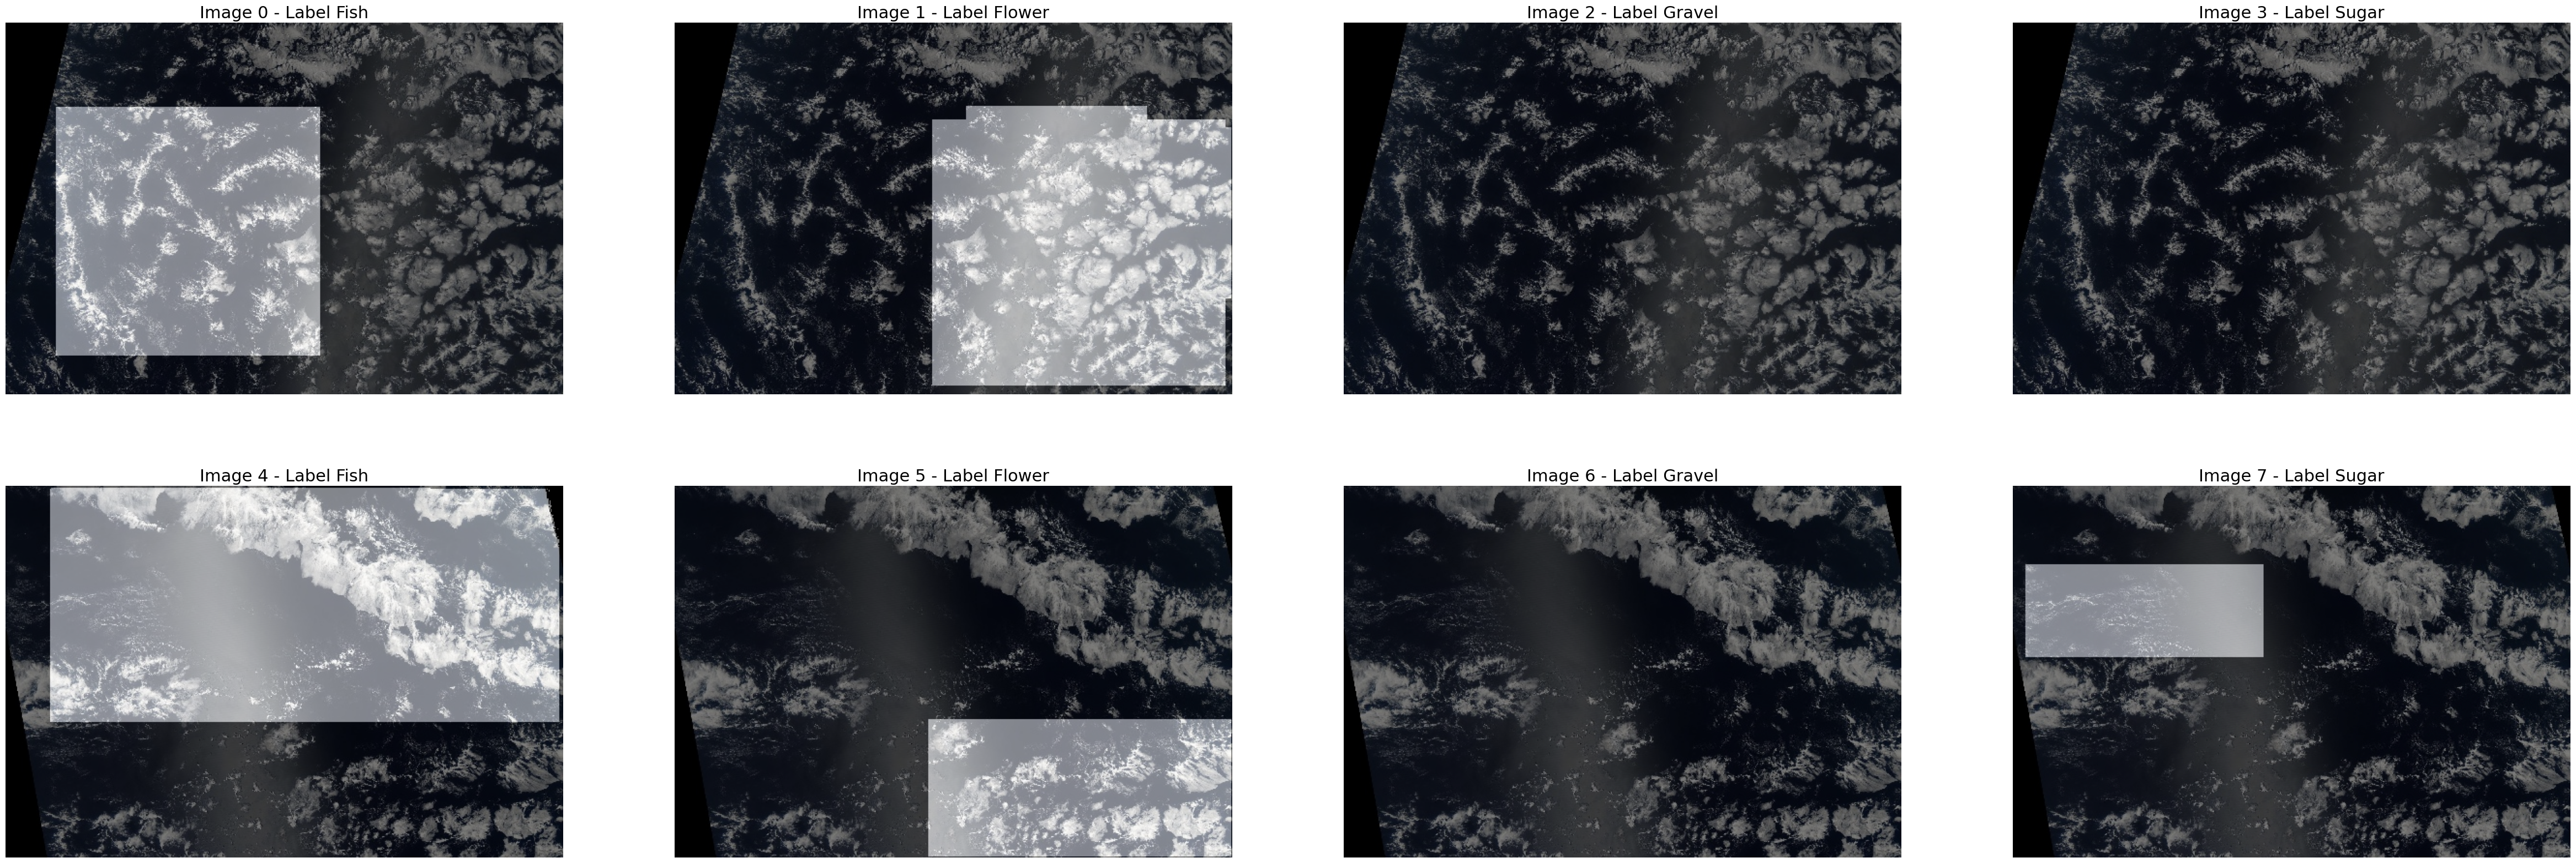

In [29]:
def rle_decode(mask_rle, shape=(384, 576)):
    s = mask_rle.split()
    starts, lengths = [np.asarray(x, dtype=int) for x in (s[0:][::2], s[1:][::2])]
    starts -= 1
    ends = starts + lengths
    img = np.zeros(shape[0]*shape[1], dtype=np.uint8)
    for lo, hi in zip(starts, ends):
        img[lo:hi] = 1
    return img.reshape(shape, order='F')  # Needed to align to RLE direction

plt.figure(figsize=[60, 20])
for index, row in train_df[:8].iterrows():
    # img = cv2.imread("../data/raw/train_images//%s" % row['Image'])[...,[2, 1, 0]] # data located on the system
    img = cv2.imread(f"/content/cloud_data/train_images/{row['Image']}")  # data located on kaggle and uploaded on colab temporarily
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mask_rle = row['EncodedPixels']
    try: # label might not be there!
        mask = rle_decode(mask_rle)
    except:
        mask = np.zeros((384, 576))
    plt.subplot(2, 4, index+1)
    plt.imshow(img)
    plt.imshow(mask, alpha=0.5, cmap='gray')
    plt.title("Image %s - Label %s" % (index, row['Class']), fontsize=22)
    plt.axis('off')    
    
plt.show()

Merge the four masks into one binary mask

In [30]:
import numpy as np
import pandas as pd

HEIGHT = 384
WIDTH = 576

# Select one image
image_name = train_df["Image"].iloc[0]

# Get all class rows belonging to that image
image_rows = train_df[train_df["Image"] == image_name]

# Start with an empty binary mask
binary_mask = np.zeros((HEIGHT, WIDTH), dtype=np.uint8)

for _, row in image_rows.iterrows():
    mask_rle = row["EncodedPixels"]

    # Decode only non-empty masks
    if pd.notna(mask_rle) and str(mask_rle).strip():
        class_mask = rle_decode(mask_rle, shape=(HEIGHT, WIDTH))

        # Add this cloud class to the binary cloud mask
        binary_mask = np.logical_or(
            binary_mask,
            class_mask
        )

# Convert True/False to 1/0 and add the channel dimension
binary_mask = binary_mask.astype(np.float32)[..., np.newaxis]

print("Image:", image_name)
print("Binary mask shape:", binary_mask.shape)
print("Unique values:", np.unique(binary_mask))

Image: 0011165.jpg
Binary mask shape: (384, 576, 1)
Unique values: [0. 1.]


Visualizing the combined cloud masks

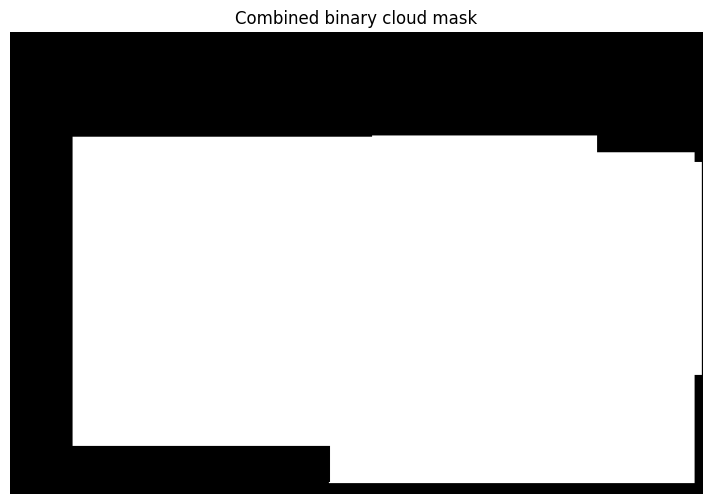

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.imshow(binary_mask[:, :, 0], cmap="gray")
plt.title("Combined binary cloud mask")
plt.axis("off")
plt.show()

Create the train/validation split

In [32]:
from sklearn.model_selection import train_test_split

image_info = (
    train_df.assign(has_mask=train_df["EncodedPixels"].notna().astype(int))
    .groupby("Image", as_index=False)["has_mask"].max()
)

train_images, val_images = train_test_split(
    image_info["Image"],
    test_size=0.2,
    random_state=42,
    stratify=image_info["has_mask"]
)

train_split_df = train_df[train_df["Image"].isin(train_images)].copy()
val_split_df = train_df[train_df["Image"].isin(val_images)].copy()          

In [33]:
print("Training images:", train_images.nunique())
print("Validation images:", val_images.nunique())
print("Overlap:", len(set(train_images) & set(val_images)))

Training images: 4436
Validation images: 1110
Overlap: 0


Define two Albumentations pipelines

In [34]:
train_transform = albu.Compose([
    albu.HorizontalFlip(p=0.5),
    albu.VerticalFlip(p=0.5),
    albu.Affine(
        scale=(0.95, 1.05),
        translate_percent=(-0.05, 0.05),
        rotate=(-10, 10),
        p=0.3
    ),
    albu.RandomBrightnessContrast(p=0.3),
    albu.GaussNoise(p=0.2),
])

Build an on-the-fly data generator

In [35]:
import os
import numpy as np
import cv2
import pandas as pd
from tensorflow import keras


class DataGenerator(keras.utils.Sequence):

    def __init__(
        self,
        image_names,
        dataframe,
        image_dir,
        batch_size=4,
        augment=False,
        shuffle=True
    ):
        self.image_names = np.array(image_names)
        self.dataframe = dataframe
        self.image_dir = image_dir
        self.batch_size = batch_size
        self.augment = augment
        self.shuffle = shuffle

        self.indexes = np.arange(len(self.image_names))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.image_names) / self.batch_size))

    def __getitem__(self, index):

        batch_indexes = self.indexes[
            index * self.batch_size:
            (index + 1) * self.batch_size
        ]

        batch_names = self.image_names[batch_indexes]

        X = []
        y = []

        for image_name in batch_names:

            # ----------------------
            # Load image
            # ----------------------
            image_path = os.path.join(
                self.image_dir,
                image_name
            )

            image = cv2.imread(image_path)
            #########
            if image is None:
               raise FileNotFoundError(
                   f"Could not load image: {image_path}"
              )
            ###########
            image = cv2.cvtColor(
                image,
                cv2.COLOR_BGR2RGB
            )

            # ----------------------
            # Create binary mask
            # ----------------------
            mask = np.zeros(
                (384, 576),
                dtype=np.uint8
            )

            rows = self.dataframe[
                self.dataframe["Image"] == image_name
            ]

            for _, row in rows.iterrows():

                if pd.notna(row["EncodedPixels"]):

                    class_mask = rle_decode(
                        row["EncodedPixels"],
                        shape=(384, 576)
                    )

                    mask = np.logical_or(
                        mask,
                        class_mask
                    )

            mask = mask.astype(np.uint8)

            # ----------------------
            # On-the-fly augmentation
            # ----------------------
            if self.augment:

                augmented = train_transform(
                    image=image,
                    mask=mask
                )

                image = augmented["image"]
                mask = augmented["mask"]

            # ----------------------
            # Normalize image
            # ----------------------
            image = (
                image.astype(np.float32)
                / 255.0
            )

            # Add mask channel
            mask = (
                mask.astype(np.float32)
                [..., np.newaxis]
            )

            X.append(image)
            y.append(mask)

        return np.array(X), np.array(y)

    def on_epoch_end(self):

        if self.shuffle:
            np.random.shuffle(self.indexes)

Training generator

In [36]:
train_generator = DataGenerator(
    image_names=train_images,
    dataframe=train_df,
    # image_dir="../data/raw/train_images",
    image_dir = "/content/cloud_data/train_images",
    batch_size=4,
    augment=True,
    shuffle=True
)

Validation generator

In [37]:
valid_generator = DataGenerator(
    image_names=val_images,
    dataframe=train_df,
    # image_dir="../data/raw/train_images",
    image_dir = "/content/cloud_data/train_images",
    batch_size=4,
    augment=False,
    shuffle=False
)

Verify the augmentation visualiy

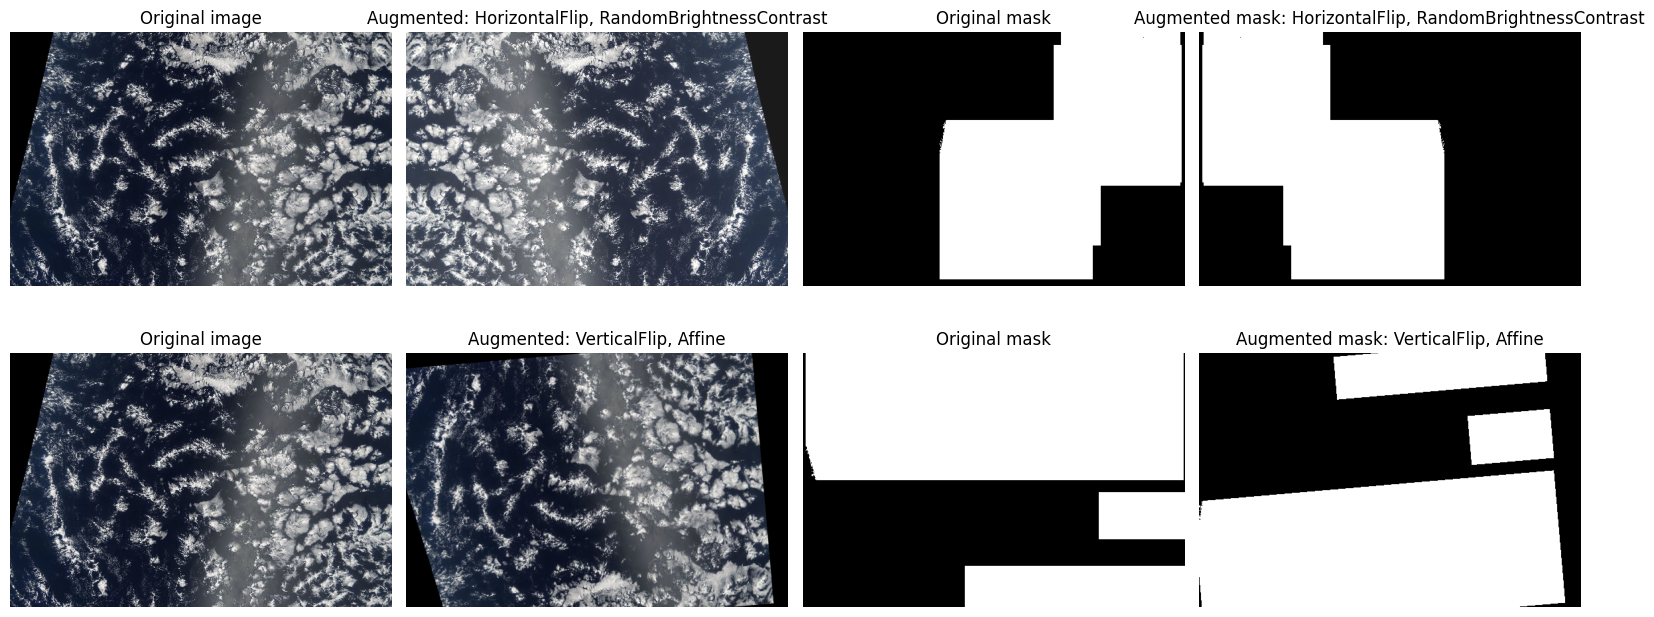

In [38]:
# Visualization transform: same augmentations, but records what was applied
vis_transform = albu.ReplayCompose([
    albu.HorizontalFlip(p=0.5),
    albu.VerticalFlip(p=0.5),
    albu.Affine(scale=(0.95, 1.05), translate_percent=(-0.05, 0.05),
                rotate=(-10, 10), p=0.3),
    albu.RandomBrightnessContrast(p=0.3),
    albu.GaussNoise(p=0.2)
])

def get_mask(name):
    rles = train_df.loc[
        (train_df["Image"] == name) & train_df["EncodedPixels"].notna(),
        "EncodedPixels"
    ]
    masks = [rle_decode(r) for r in rles]
    return np.maximum.reduce(masks) if masks else np.zeros((384, 576))

fig, ax = plt.subplots(2, 4, figsize=(16, 7))

for i, name in enumerate(list(train_images)[:2]):
    img = cv2.cvtColor(
        # cv2.imread(f"../data/raw/train_images/{name}"),  # data located on the system
        cv2.imread(f"/content/cloud_data/train_images/{row['Image']}"),  # data located on kaggle and uploaded on colab temporarily
        cv2.COLOR_BGR2RGB
    )
    mask = get_mask(name)

    aug = vis_transform(image=img, mask=mask)

    applied = [
        t["__class_fullname__"].split(".")[-1]
        for t in aug["replay"]["transforms"] if t["applied"]
    ]
    aug_name = ", ".join(applied) or "No augmentation"

    ax[i, 0].imshow(img)
    ax[i, 0].set_title("Original image")

    ax[i, 1].imshow(aug["image"])
    ax[i, 1].set_title(f"Augmented: {aug_name}")

    ax[i, 2].imshow(mask, cmap="gray")
    ax[i, 2].set_title("Original mask")

    ax[i, 3].imshow(aug["mask"], cmap="gray")
    ax[i, 3].set_title(f"Augmented mask: {aug_name}")

    for a in ax[i]:
        a.axis("off")

plt.tight_layout()
plt.show()

Build a simple U-Net

In [39]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    return x


def build_unet(input_shape=(384, 576, 3)):
    inputs = keras.Input(input_shape)

    # Encoder
    c1 = conv_block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 32)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 64)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 128)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    b = conv_block(p4, 256)

    # Decoder
    u4 = layers.Conv2DTranspose(128, 2, strides=2, padding="same")(b)
    u4 = layers.Concatenate()([u4, c4])
    u4 = conv_block(u4, 128)

    u3 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(u4)
    u3 = layers.Concatenate()([u3, c3])
    u3 = conv_block(u3, 64)

    u2 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(u3)
    u2 = layers.Concatenate()([u2, c2])
    u2 = conv_block(u2, 32)

    u1 = layers.Conv2DTranspose(16, 2, strides=2, padding="same")(u2)
    u1 = layers.Concatenate()([u1, c1])
    u1 = conv_block(u1, 16)

    # Binary mask: cloud / non-cloud
    outputs = layers.Conv2D(1, 1, activation="sigmoid")(u1)

    return keras.Model(inputs, outputs)


model = build_unet()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 384, 576,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 384, 576,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 384, 576,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 192, 288,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 192, 288,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 192, 288,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 96, 144,   │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 96, 144,   │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 96, 144,   │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 48, 72,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 48, 72,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 48, 72,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 24, 36,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 24, 36,    │    295,168 │ max_pooling2d_3[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 24, 36,    │    590,080 │ conv2d_8[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 48, 72,    │    131,200 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 48, 72,    │          0 │ conv2d_transpose

 Total params: 1,941,105 (7.40 MB)

 Trainable params: 1,941,105 (7.40 MB)

 Non-trainable params: 0 (0.00 B)

Define Dice, IoU and loss

In [49]:
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)

    return (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true) +
        tf.reduce_sum(y_pred) +
        smooth
    )


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


def bce_dice_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)


def iou_coef(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)

    y_pred = tf.cast(y_pred > 0.5, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection

    return (intersection + smooth) / (union + smooth)

In [42]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


Compile the model

In [66]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=bce_dice_loss,
    metrics=[dice_coef, iou_coef]
)

Add callbacks

In [51]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_unet.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-7
    )
]

Train with your generators

In [36]:
history = model.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


1109/1109 ━━━━━━━━━━━━━━━━━━━━ 184s 139ms/step - dice_coef: 0.6183 - iou_coef: 0.5610 - loss: 1.0017 - val_dice_coef: 0.6607 - val_iou_coef: 0.5799 - val_loss: 0.9658 - learning_rate: 1.0000e-04
Epoch 2/30
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 150s 135ms/step - dice_coef: 0.6486 - iou_coef: 0.5871 - loss: 0.9332 - val_dice_coef: 0.6665 - val_iou_coef: 0.5850 - val_loss: 0.9367 - learning_rate: 1.0000e-04
Epoch 3/30
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 151s 136ms/step - dice_coef: 0.6532 - iou_coef: 0.5883 - loss: 0.9246 - val_dice_coef: 0.6720 - val_iou_coef: 0.5876 - val_loss: 0.9347 - learning_rate: 1.0000e-04
Epoch 4/30
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 151s 136ms/step - dice_coef: 0.6559 - iou_coef: 0.5907 - loss: 0.9158 - val_dice_coef: 0.6622 - val_iou_coef: 0.5862 - val_loss: 0.9147 - learning_rate: 1.0000e-04
Epoch 5/30
1109/1109 ━━━━━━━━━━━━━━━━━━━━ 150s 135ms/step - dice_coef: 0.6593 - iou_coef: 0.5924 - loss: 0.9090 - val_dice_coef: 0.6578 - val_iou_coef: 0.5910 - val_loss: 0.9185 - learnin

Save the model on system

In [52]:
from google.colab import files

files.download("/content/best_unet.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
import os

print("Current folder:", os.getcwd())
print("Exists:", os.path.exists("best_unet.keras"))
print("Full path:", os.path.abspath("best_unet.keras"))

Current folder: /content
Exists: True
Full path: /content/best_unet.keras


Save the model on google drive

In [45]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [46]:
import os

MODEL_DIR = "/content/drive/MyDrive/cloud_segmentation/models"

os.makedirs(MODEL_DIR, exist_ok=True)

In [47]:
import shutil

shutil.copy(
    "/content/best_unet.keras",
    "/content/drive/MyDrive/cloud_segmentation/models/best_unet.keras"
)

'/content/drive/MyDrive/cloud_segmentation/models/best_unet.keras'

In [48]:
import os

path = "/content/drive/MyDrive/cloud_segmentation/models/best_unet.keras"

print(os.path.exists(path))
print(path)

True
/content/drive/MyDrive/cloud_segmentation/models/best_unet.keras


In [62]:
## Load the model

# from google.colab import drive
# from tensorflow import keras

# drive.mount("/content/drive")

# model = keras.models.load_model(
#     "/content/drive/MyDrive/cloud_segmentation/models/best_unet.keras"
# )

In [ ]:
## Load the model
from google.colab import drive
from tensorflow import keras

drive.mount("/content/drive")

model = keras.models.load_model(
    "/content/drive/MyDrive/cloud_segmentation/models/best_unet.keras",
    compile=False
)

print("Model loaded successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model loaded successfully!


Plot training results

In [55]:
X_val, y_val = valid_generator[0]

pred_prob = model.predict(X_val[:2])
pred_mask = (pred_prob > 0.5).astype(np.uint8)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [63]:
## prediction for all validation data
pred_prob = model.predict(valid_generator)
pred_mask = (pred_prob > 0.7).astype(np.uint8)   

278/278 ━━━━━━━━━━━━━━━━━━━━ 424s 2s/step


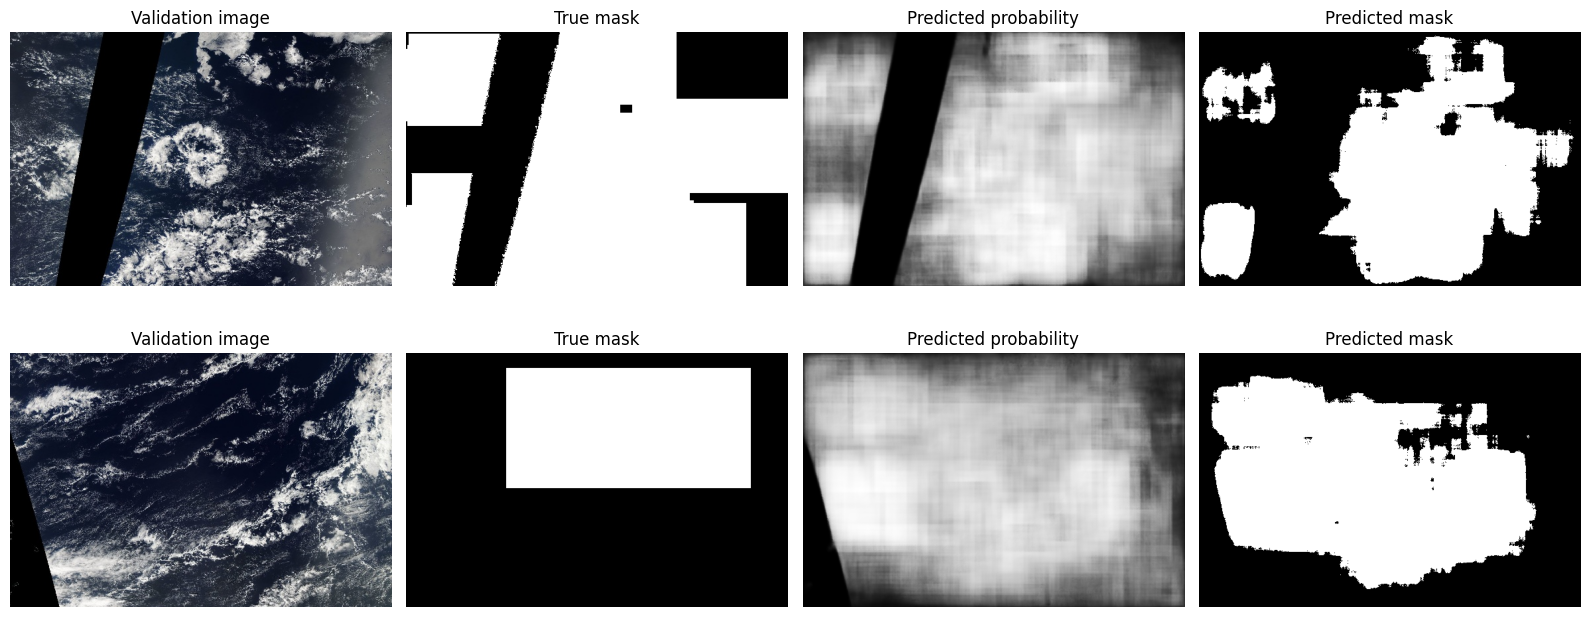

In [64]:
## visualizes the prediction results for 2 validation images

fig, ax = plt.subplots(2, 4, figsize=(16, 7))

for i in range(2):

    ax[i, 0].imshow(X_val[i])
    ax[i, 0].set_title("Validation image")

    ax[i, 1].imshow(y_val[i, :, :, 0], cmap="gray")
    ax[i, 1].set_title("True mask")

    ax[i, 2].imshow(pred_prob[i, :, :, 0], cmap="gray")
    ax[i, 2].set_title("Predicted probability")

    ax[i, 3].imshow(pred_mask[i, :, :, 0], cmap="gray")
    ax[i, 3].set_title("Predicted mask")

    for a in ax[i]:
        a.axis("off")

plt.tight_layout()
plt.show()

In [67]:
results = model.evaluate(
    valid_generator,
    return_dict=True
)

print(results)

278/278 ━━━━━━━━━━━━━━━━━━━━ 445s 2s/step - dice_coef: 0.6902 - iou_coef: 0.6094 - loss: 0.8420
{'dice_coef': 0.6902322173118591, 'iou_coef': 0.6094122529029846, 'loss': 0.8420307636260986}


In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()

plt.show()

NameError: name 'history' is not defined

<Figure size 800x500 with 0 Axes>

278/278 ━━━━━━━━━━━━━━━━━━━━ 426s 2s/step - dice_coef: 0.6902 - iou_coef: 0.6094 - loss: 0.8420


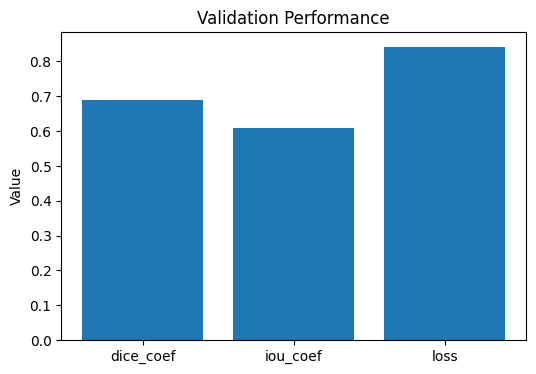

In [75]:
import matplotlib.pyplot as plt

results = model.evaluate(
    valid_generator,
    return_dict=True
)

plt.figure(figsize=(6, 4))

plt.bar(
    list(results.keys()),
    list(results.values())
)

plt.title("Validation Performance")
plt.ylabel("Value")

plt.show()

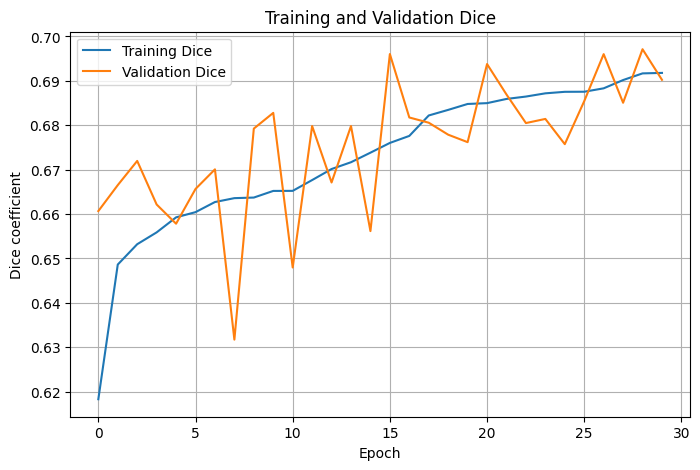

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["dice_coef"], label="Training Dice")
plt.plot(history.history["val_dice_coef"], label="Validation Dice")

plt.xlabel("Epoch")
plt.ylabel("Dice coefficient")
plt.title("Training and Validation Dice")
plt.legend()
plt.grid()

plt.show()

In [53]:
TEST_DIR = "/content/cloud_data/test_images"

In [54]:
import os
import numpy as np
import cv2
from tensorflow import keras


class TestGenerator(keras.utils.Sequence):

    def __init__(self, image_names, image_dir, batch_size=4):
        self.image_names = np.array(image_names)
        self.image_dir = image_dir
        self.batch_size = batch_size

    def __len__(self):
        return int(np.ceil(len(self.image_names) / self.batch_size))

    def __getitem__(self, index):

        batch_names = self.image_names[
            index * self.batch_size:
            (index + 1) * self.batch_size
        ]

        X = []

        for image_name in batch_names:

            image_path = os.path.join(
                self.image_dir,
                image_name
            )

            image = cv2.imread(image_path)

            if image is None:
                raise FileNotFoundError(
                    f"Could not load: {image_path}"
                )

            image = cv2.cvtColor(
                image,
                cv2.COLOR_BGR2RGB
            )

            # Same normalization used during training
            image = image.astype(np.float32) / 255.0

            X.append(image)

        return np.array(X)

In [55]:
TEST_DIR = "/content/cloud_data/test_images"

test_images = sorted([
    f for f in os.listdir(TEST_DIR)
    if f.lower().endswith(".jpg")
])

print("Number of test images:", len(test_images))
print(test_images[:5])

Number of test images: 3698
['002f507.jpg', '0035ae9.jpg', '0038327.jpg', '004f759.jpg', '005ba08.jpg']


In [56]:
test_generator = TestGenerator(
    image_names=test_images,
    image_dir=TEST_DIR,
    batch_size=4
)

In [57]:
X_test = test_generator[0]

pred_prob = model.predict(X_test)

pred_mask = (
    pred_prob > 0.5
).astype(np.uint8)

print("Images:", X_test.shape)
print("Probabilities:", pred_prob.shape)
print("Masks:", pred_mask.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Images: (4, 384, 576, 3)
Probabilities: (4, 384, 576, 1)
Masks: (4, 384, 576, 1)


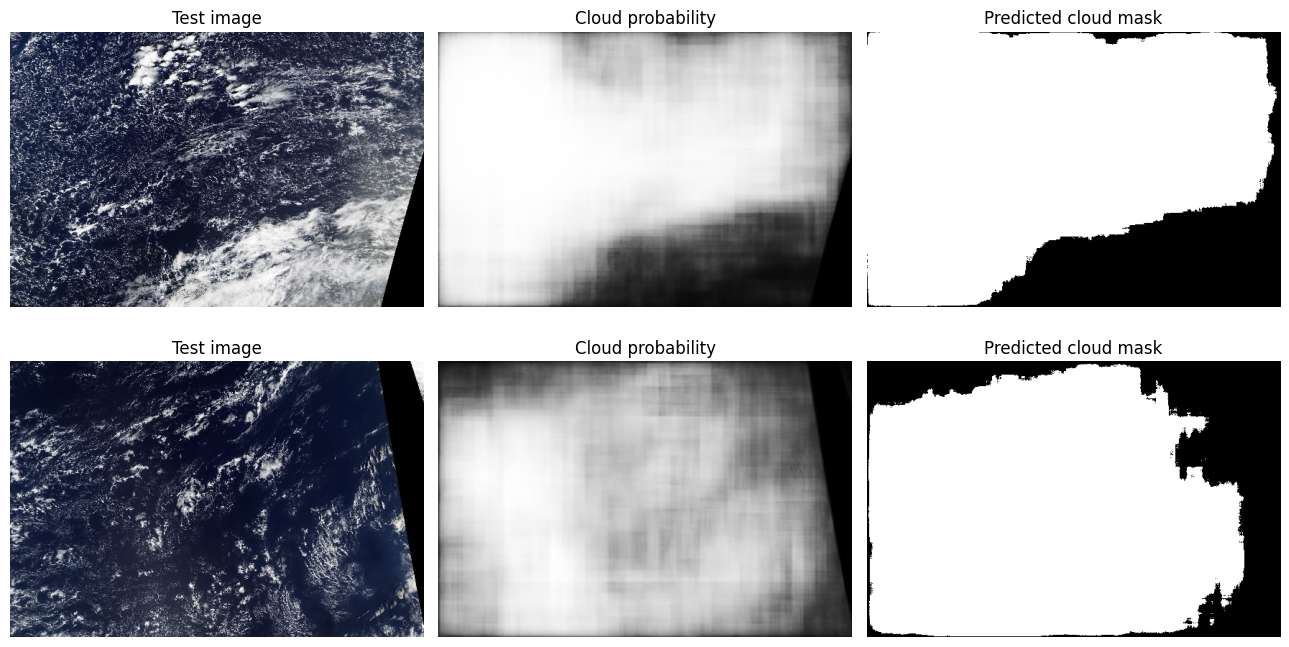

In [58]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 3, figsize=(13, 7))

for i in range(2):

    ax[i, 0].imshow(X_test[i])
    ax[i, 0].set_title("Test image")

    ax[i, 1].imshow(
        pred_prob[i, :, :, 0],
        cmap="gray"
    )
    ax[i, 1].set_title("Cloud probability")

    ax[i, 2].imshow(
        pred_mask[i, :, :, 0],
        cmap="gray"
    )
    ax[i, 2].set_title("Predicted cloud mask")

    for a in ax[i]:
        a.axis("off")

plt.tight_layout()
plt.show()

In [59]:
pred_prob = model.predict(test_generator)

925/925 ━━━━━━━━━━━━━━━━━━━━ 33s 35ms/step


: 

: 

: 

In [1]:
X_val, y_val = valid_generator[0]

pred_prob = model.predict(X_val)
pred_mask = (pred_prob > 0.5).astype(np.uint8)

fig, ax = plt.subplots(2, 3, figsize=(14, 7))

for i in range(2):

    ax[i, 0].imshow(X_val[i])
    ax[i, 0].set_title("Validation image")

    ax[i, 1].imshow(y_val[i, :, :, 0], cmap="gray")
    ax[i, 1].set_title("True mask")

    ax[i, 2].imshow(pred_mask[i, :, :, 0], cmap="gray")
    ax[i, 2].set_title("Predicted mask")

    for a in ax[i]:
        a.axis("off")

plt.tight_layout()
plt.show()

NameError: name 'valid_generator' is not defined